# 01 · The simulated stock history

No facility-level stock history is public, so the monthly reports for the 28 real PHCs are simulated. This notebook checks that the simulation is internally consistent and shows the patterns an LGA officer actually faces: missing reports, late reports, stockouts that hide true demand, and rare shortages.

Everything below the facility level is **simulated** (seed 20261004).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from supplysignal.features import build_feature_panel, prepare_ledger
from supplysignal.pipeline import SEED, build, load_facilities, simulate_ledger

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LEDGER = PROJECT / "data/processed/synthetic_lmis.csv"
OUT = PROJECT / "reports/analysis"
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, RED = "#237a80", "#c35c43"

## 1. Load the ledger and check its integrity

The ledger is generated on first run. Every submitted report must balance (opening + receipts − consumption − losses + adjustments = closing), keys must be unique, and missing reports must stay blank rather than become zeros.

In [2]:
if not LEDGER.exists():
    build()

ledger = prepare_ledger(pd.read_csv(LEDGER))
ledger["missing"] = ledger.report_status.eq("missing")
ledger["shortage"] = ledger.truth_unmet_units.gt(0)
ledger["delay_days"] = (ledger.submitted_at - (ledger.period + pd.offsets.MonthBegin(1))).dt.days
observed = ledger.loc[~ledger.missing].copy()

imbalance = (
    observed.opening_stock + observed.receipts - observed.consumption
    - observed.losses + observed.adjustments - observed.closing_stock
)
integrity = pd.Series({
    "rows": len(ledger),
    "facility-product series": ledger.groupby(["facility_id", "commodity_id"]).ngroups,
    "duplicate keys": int(ledger.duplicated(["facility_id", "commodity_id", "period"]).sum()),
    "missing reports": int(ledger.missing.sum()),
    "unbalanced reports": int(imbalance.ne(0).sum()),
    "negative quantities": int(observed[["opening_stock", "receipts", "consumption", "closing_stock"]].lt(0).any(axis=1).sum()),
})
assert integrity["duplicate keys"] == 0 and integrity["unbalanced reports"] == 0
assert ledger.loc[ledger.missing, ["consumption", "closing_stock"]].isna().all().all()
integrity.to_frame("count")

,count
rows,2016
facility-product series,84
duplicate keys,0
missing reports,103
unbalanced reports,0
negative quantities,0


## 2. Missing and late reports

Two separate problems: some reports never arrive, and those that do arrive weeks after the month ends. The heatmap shows the share of each PHC's three product reports missing per month; the histogram shows how late submitted reports are.

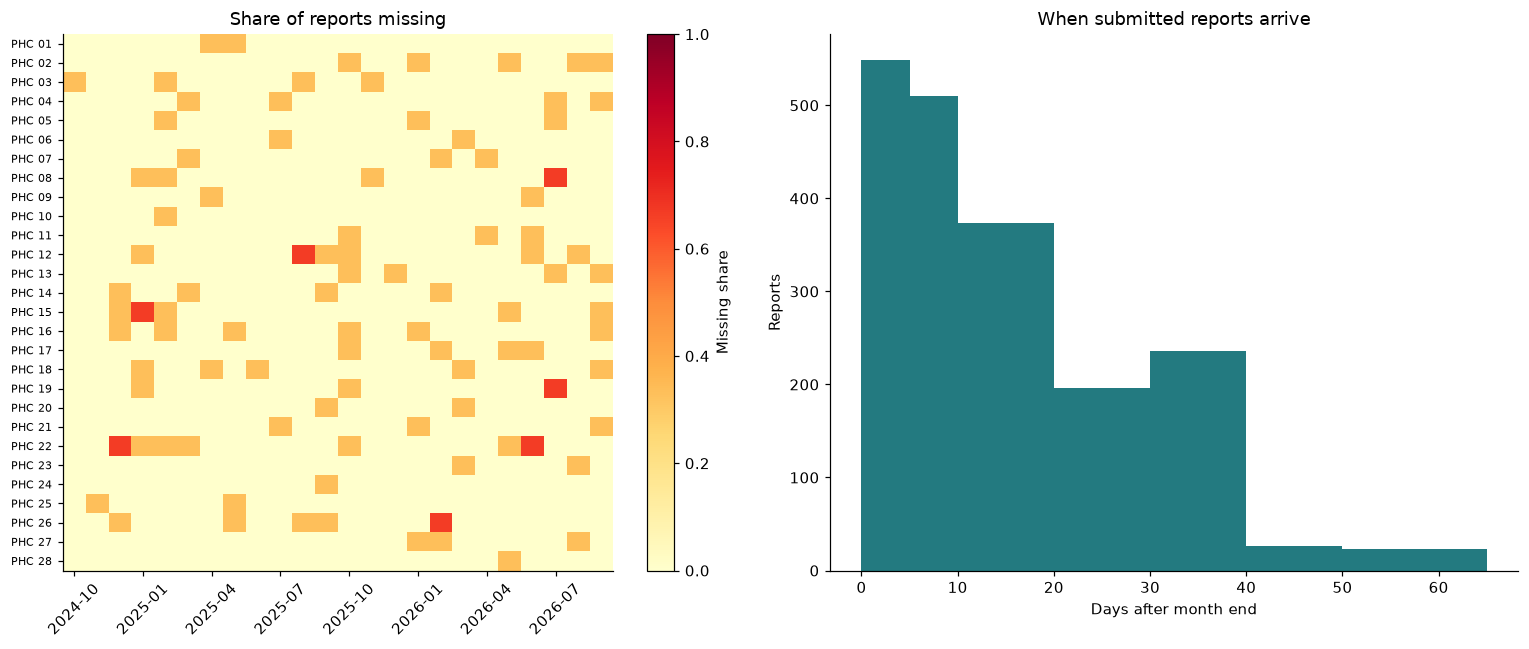

Reports missing: 5.1%
Median delay of submitted reports: 8 days after month end


In [3]:
missing_share = ledger.groupby(["facility_id", "period"]).missing.mean().unstack()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
image = axes[0].imshow(missing_share, aspect="auto", vmin=0, vmax=1, cmap="YlOrRd")
axes[0].set_yticks(range(len(missing_share)), [f"PHC {i + 1:02}" for i in range(len(missing_share))], fontsize=7)
axes[0].set_xticks(range(0, len(missing_share.columns), 3), [month.strftime("%Y-%m") for month in missing_share.columns[::3]], rotation=45)
axes[0].set_title("Share of reports missing")
fig.colorbar(image, ax=axes[0], label="Missing share")
axes[1].hist(observed.delay_days, bins=[0, 5, 10, 20, 30, 40, 50, 65], color=TEAL)
axes[1].set(xlabel="Days after month end", ylabel="Reports", title="When submitted reports arrive")
fig.tight_layout()
plt.show()

print(f"Reports missing: {ledger.missing.mean():.1%}")
print(f"Median delay of submitted reports: {observed.delay_days.median():.0f} days after month end")

## 3. How fresh is the evidence at forecast time?

Late arrival means that on the day a forecast is made, the newest visible report is often more than a month old. This is the core information gap SupplySignal is built around.

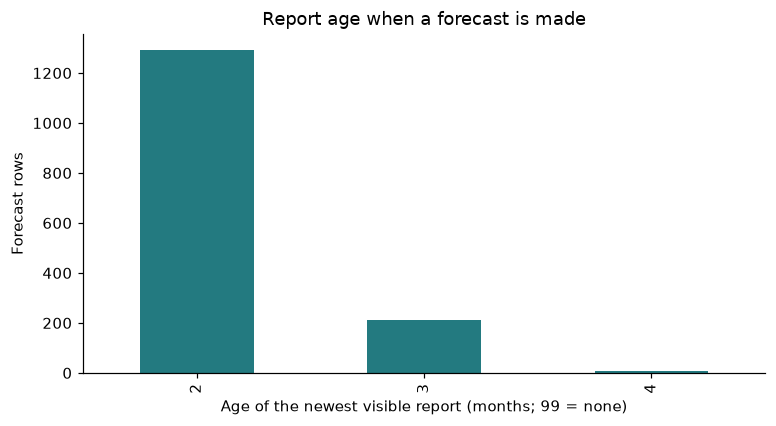

Forecasts relying on a report older than one month: 100.0%


In [4]:
panel = build_feature_panel(ledger, "2025-04-01")

fig, ax = plt.subplots(figsize=(8, 4))
panel.report_age_months.fillna(99).value_counts().sort_index().plot.bar(ax=ax, color=TEAL)
ax.set(xlabel="Age of the newest visible report (months; 99 = none)", ylabel="Forecast rows", title="Report age when a forecast is made")
plt.show()

print(f"Forecasts relying on a report older than one month: {panel.report_age_months.gt(1).mean():.1%}")

## 4. Shortages are rare events

Shortage months are few, so a model that always predicts "no shortage" would look accurate while being useless. Evaluation in later notebooks therefore counts shortages found per call, not accuracy.

,rows,shortage_months,shortage_rate
report_status,,,
missing,103,2,0.019417
reported,1913,40,0.020910


,rows,shortage_months,missing_reports,unmet_units
commodity_id,,,,
magnesium_sulfate,672,14,38,36
misoprostol,672,16,32,95
oxytocin,672,12,33,57


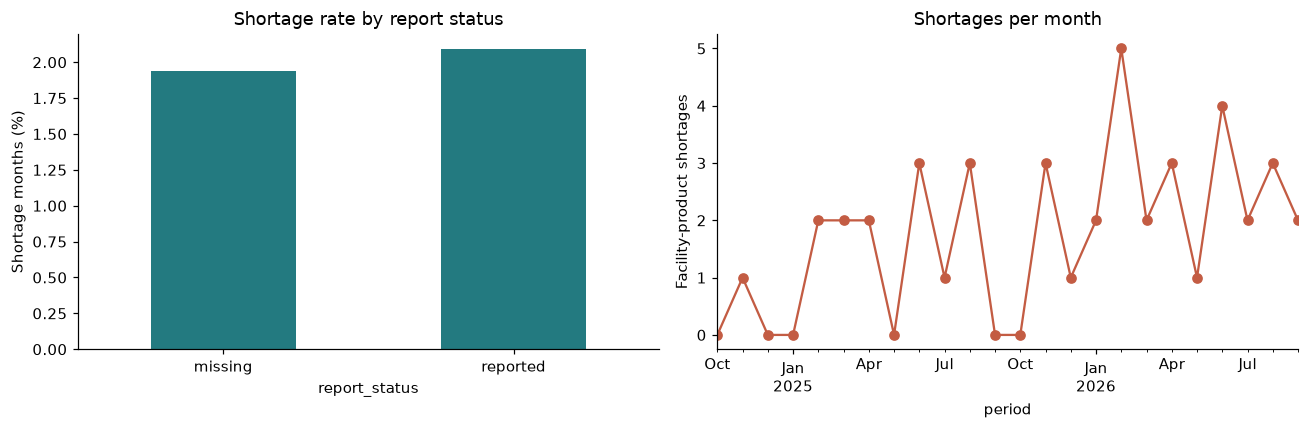

Shortage months: 42 of 2016 (2.08%)


In [5]:
by_status = ledger.groupby("report_status").agg(
    rows=("shortage", "size"), shortage_months=("shortage", "sum"), shortage_rate=("shortage", "mean")
)
by_product = ledger.groupby("commodity_id").agg(
    rows=("shortage", "size"),
    shortage_months=("shortage", "sum"),
    missing_reports=("missing", "sum"),
    unmet_units=("truth_unmet_units", "sum"),
)
display(by_status)
display(by_product)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(by_status.shortage_rate * 100).plot.bar(ax=axes[0], color=TEAL, rot=0)
axes[0].set(ylabel="Shortage months (%)", title="Shortage rate by report status")
ledger.groupby("period").shortage.sum().plot(ax=axes[1], marker="o", color=RED)
axes[1].set(ylabel="Facility-product shortages", title="Shortages per month")
fig.tight_layout()
plt.show()

print(f"Shortage months: {int(ledger.shortage.sum())} of {len(ledger)} ({ledger.shortage.mean():.2%})")

## 5. Demand, censoring and seasonality

Reported consumption cannot exceed the stock on the shelf, so in a stockout month it understates true demand. Those months are excluded from the demand model's training labels. Demand is plotted per product because units differ. The simulation includes a June–September demand rise.

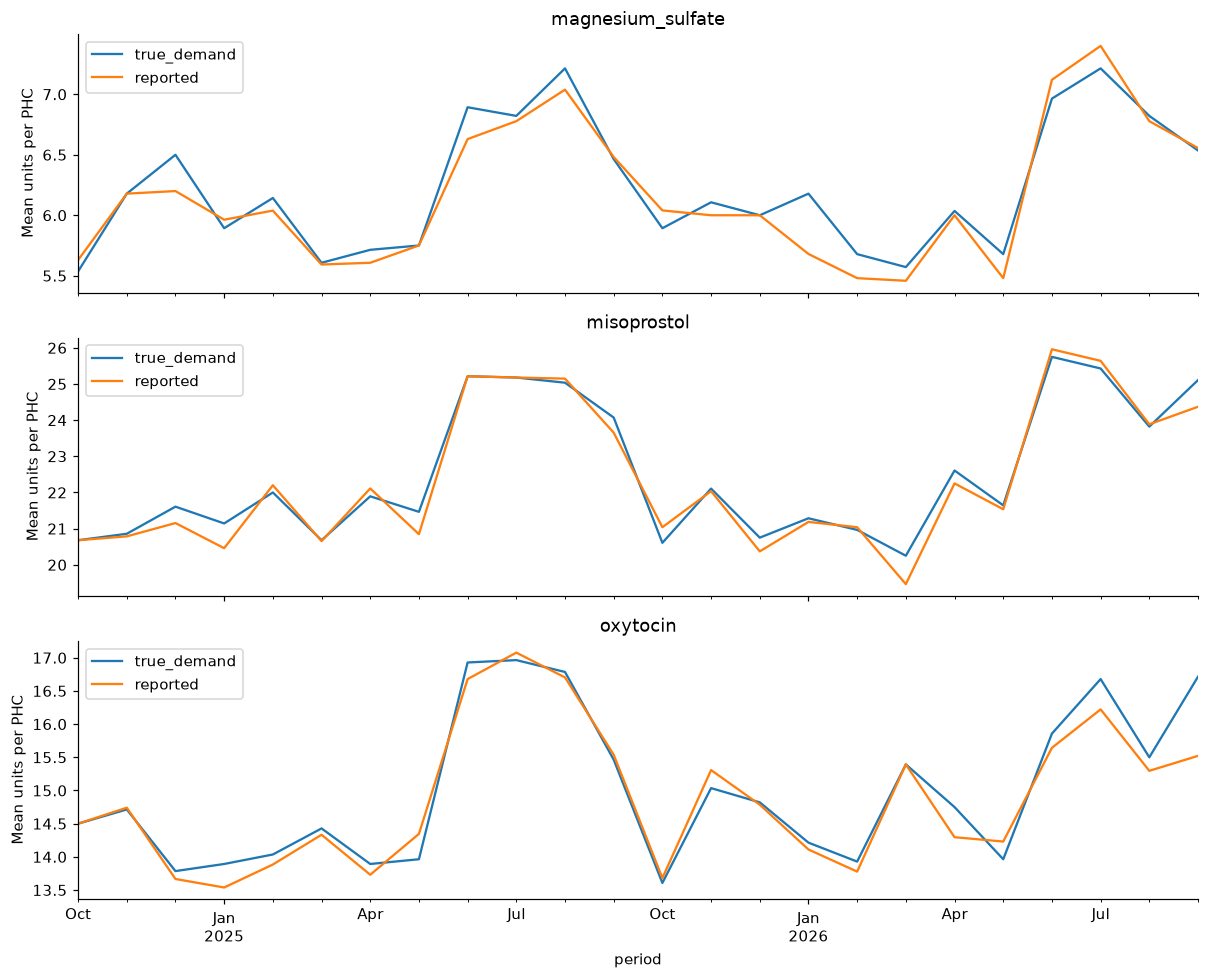

,submitted_reports,excluded_from_labels
commodity_id,,
magnesium_sulfate,634,20
misoprostol,640,16
oxytocin,639,14


In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (product, group) in zip(axes, ledger.groupby("commodity_id")):
    group.groupby("period").agg(true_demand=("truth_latent_demand", "mean"), reported=("consumption", "mean")).plot(ax=ax)
    ax.set(title=product, ylabel="Mean units per PHC")
fig.tight_layout()
plt.show()

censored = observed.stockout_days.gt(0) | observed.closing_stock.eq(0)
observed.assign(censored=censored).groupby("commodity_id").agg(
    submitted_reports=("censored", "size"), excluded_from_labels=("censored", "sum")
)

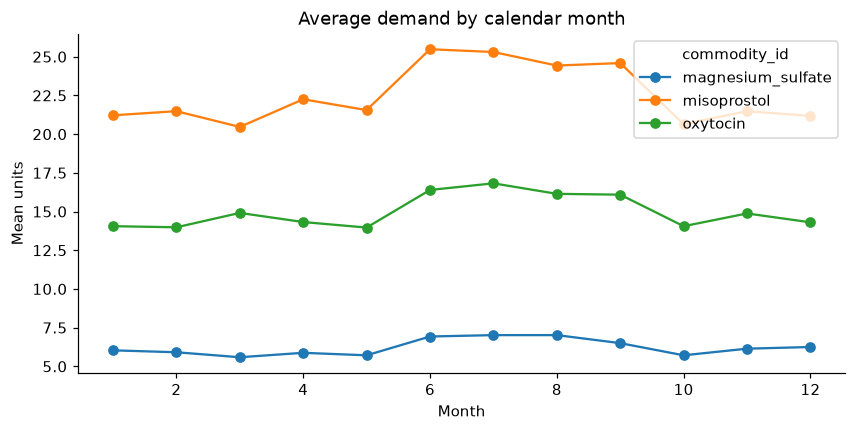

In [7]:
seasonal = ledger.assign(month=ledger.period.dt.month).groupby(["commodity_id", "month"]).truth_latent_demand.mean().unstack(0)

fig, ax = plt.subplots(figsize=(9, 4))
seasonal.plot(ax=ax, marker="o")
ax.set(title="Average demand by calendar month", xlabel="Month", ylabel="Mean units")
plt.show()

## 6. Sensitivity to the random seed

Regenerating the history with five other seeds shows how much the shortage count varies by chance alone, so results are not read off a single lucky draw.

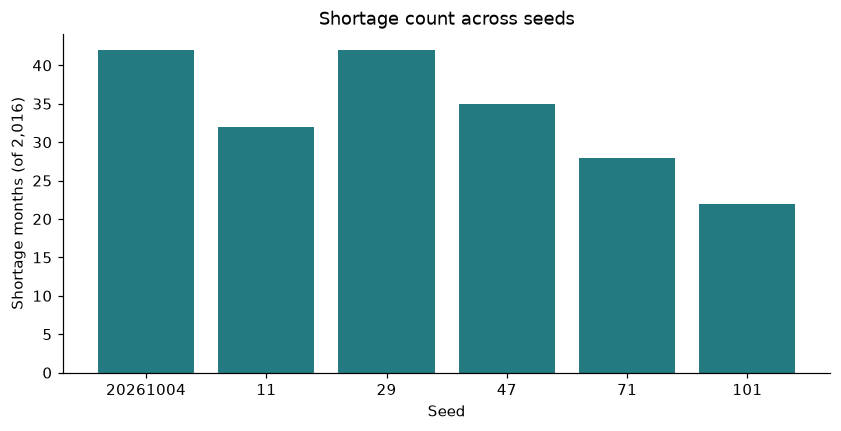

,seed,missing_pct,shortage_months,shortage_pct
0,20261004,5.109127,42,2.083333
1,11,4.265873,32,1.587302
2,29,4.315476,42,2.083333
3,47,5.059524,35,1.736111
4,71,3.323413,28,1.388889
5,101,4.315476,22,1.091270


In [8]:
seed_rows = []
for seed in [SEED, 11, 29, 47, 71, 101]:
    generated = pd.DataFrame(simulate_ledger(load_facilities(), seed=seed))
    shortages = generated.truth_unmet_units.gt(0)
    seed_rows.append({
        "seed": seed,
        "missing_pct": generated.report_status.eq("missing").mean() * 100,
        "shortage_months": int(shortages.sum()),
        "shortage_pct": shortages.mean() * 100,
    })
seeds = pd.DataFrame(seed_rows)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(seeds.seed.astype(str), seeds.shortage_months, color=TEAL)
ax.set(xlabel="Seed", ylabel="Shortage months (of 2,016)", title="Shortage count across seeds")
plt.show()
seeds

## 7. Simulation design choices

How each mechanism is generated, and what that means when reading later results.

In [9]:
design = pd.DataFrame(
    [
        ["Missing reports", "Random 4.5% plus one scripted silent clinic", "Missingness flags a check, not a confirmed shortage"],
        ["Demand", "Facility size multiplier, bounded noise, June–September rise", "Calendar features can help the model"],
        ["Resupply", "Triggered by low stock; 10% of deliveries fail", "Receipts between reports are the main unknown"],
        ["Stock balances", "Always balance; losses and adjustments are zero", "Real imports are validated for imbalance separately"],
        ["Products", "All three products at every PHC", "Real eligibility comes from the LGA roster"],
        ["Stockout days", "Derived from the unmet share of the month", "A monthly measure, not a daily stock path"],
    ],
    columns=["Mechanism", "How it is simulated", "Implication"],
)
design.to_csv(OUT / "simulator_limitations.csv", index=False)
design

,Mechanism,How it is simulated,Implication
0,Missing reports,Random 4.5% plus one scripted silent clinic,"Missingness flags a check, not a confirmed sho..."
1,Demand,"Facility size multiplier, bounded noise, June–...",Calendar features can help the model
2,Resupply,Triggered by low stock; 10% of deliveries fail,Receipts between reports are the main unknown
3,Stock balances,Always balance; losses and adjustments are zero,Real imports are validated for imbalance separ...
4,Products,All three products at every PHC,Real eligibility comes from the LGA roster
5,Stockout days,Derived from the unmet share of the month,"A monthly measure, not a daily stock path"


In [10]:
findings = {
    "rows": len(ledger),
    "missing_reports": int(ledger.missing.sum()),
    "median_delay_days": float(observed.delay_days.median()),
    "stale_feature_pct": float(panel.report_age_months.gt(1).mean() * 100),
    "shortage_events": int(ledger.shortage.sum()),
    "censored_observed_rows": int(censored.sum()),
    "seed_min_events": int(seeds.shortage_months.min()),
    "seed_max_events": int(seeds.shortage_months.max()),
}
(OUT / "synthetic_findings.json").write_text(json.dumps(findings, indent=2))
findings

{'rows': 2016,
 'missing_reports': 103,
 'median_delay_days': 8.0,
 'stale_feature_pct': 100.0,
 'shortage_events': 42,
 'censored_observed_rows': 50,
 'seed_min_events': 22,
 'seed_max_events': 42}

## What this means

- **Fresh evidence is the bottleneck.** Most forecasts are made from a report more than a month old, and reports miss deliveries made since. The app turns each flag into a verification call for that reason.
- **Missing reports are a reason to check, not a verdict.** Silence is surfaced as its own worklist signal.
- **Shortages are rare.** Methods are compared on shortages found per call, not on accuracy.
- **Stockout months hide true demand.** They are excluded from the demand model's labels (notebook 02).